# Vinante et al. (2020): a micromagnet levitated above a superconductor

A. Vinante, P. Falferi, G. Gasbarri, A. Setter, C. Timberlake and H. Ulbricht, *Ultralow Mechanical
Damping with Meissner-Levitated Ferromagnetic Microparticles*, Phys. Rev. Applied **13**, 064027
(2020), [doi:10.1103/PhysRevApplied.13.064027](https://doi.org/10.1103/PhysRevApplied.13.064027)
(open version arXiv:1912.12252v3, from which the numbers below are taken).

A Nd-alloy microsphere (radius 27 ± 1 μm by microscope, μ0M ≈ 0.71 T, ρ = 7430 kg/m³) levitates in a
4 mm cylindrical well in lead at 4.2 K. The Meissner currents of the bottom surface act as an image
dipole: the magnet floats at a height z0 with its moment parallel to the surface, and its vertical
(z) and tilt (β) modes follow from the image method alone, ωz = √(4g/z0) and ωβ = √(5z0g/3R²)
(Eqs. (5), (6)). Their product gives the radius independently of density and magnetisation,
R = √(20/3)·g/(ωzωβ) (Eq. (7)). The modes are measured at 56.5 ± 0.1 Hz and 377 ± 5 Hz, with
ringdown times beyond 10⁴ s and Q > 10⁷.

This notebook builds the system from `MeissnerImagePlane` (the image dipole of an ideal
superconducting plane) and `Gravity` in a `Trap`, and

1. computes z0, ωz and ωβ and inverts Eq. (7) for the measured frequencies;
2. simulates large-amplitude z and β oscillations in `RigidBodySimulation` and compares the
   softening with the paper's Eqs. (B5) and (B6);
3. compares levisim's gas damping (helium at 4.2 K) with the paper's Eqs. (8) and (9) and its fitted
   slopes.

**Comparisons stated before running:** z0 = 311 μm, 56.5 Hz and 377 Hz with R = 30.1 μm (the paper's
Eq. (7) radius, with which it reproduces both frequencies); R = 30.1 ± 0.5 μm from Eq. (7);
ω̃z = ωz(1 − (35/48)z_A²/z0²) and ω̃β = ωβ(1 − β_A²/4); 1/τ per mbar 5.96 (z) and 5.35 (β) s⁻¹ from
Eqs. (8), (9), measured 6.2 ± 0.5 and 5.6 ± 0.3 s⁻¹/mbar.

| Quantity | Value used | Source |
|---|---|---|
| particle | sphere, R = 30.1 μm (Eq. (7)) or 27 μm (microscope), ρ = 7430 kg/m³, μ0M = 0.71 T | text |
| trap | infinite plane (the well's bottom; z0 ≪ the 2 mm well radius) | text |
| gas | helium at 4.2 K | text |

Axes: gravity is levisim's default −x, so the paper's height z is levisim's x; the moment lies along
y, and the paper's tilt β (of the moment towards the vertical) is the rotation about z, levisim's `'γ'`.
The side walls, which confine x, y and the azimuth α in the experiment, are not modelled.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from levisim.core.constants import g, kB, μ0, π
from levisim.core.logger import logger
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.units import mbar
from levisim.physics import Gas, Sphere, Trap
from levisim.physics.fields import Gravity, MeissnerImagePlane, meissner_levitation_height
from levisim.physics.material import Material
from levisim.physics.particle import body_axis_to_quaternion
from levisim.simulation import RigidBodySimulation

logger.remove()
set_plt_rcParams_to_xmgrace_style()
t_start = time.time()

MAGNET = Material('Nd alloy (Vinante et al. 2020)', 7430.0, magnetisation=0.71 / μ0)
m_He = 4.002602 * 1.66053906660e-27


def levitated(R, P=1e-4*mbar):
    particle = Sphere(R, material=MAGNET, orientation=body_axis_to_quaternion((0, 1, 0)))
    μ = np.linalg.norm(particle.magnetic_moment)
    h0 = meissner_levitation_height(μ, particle.m)
    plane = MeissnerImagePlane(surface_point=(-h0, 0, 0), normal=(1, 0, 0))
    gas = Gas(P=P, T=4.2, m=m_He)
    return Trap(particle=particle, fields=[plane, Gravity()], gas=gas), h0

## 1. Levitation height and the two image-method modes

In [2]:
for R in (30.1e-6, 27e-6):
    trap, h0 = levitated(R)
    p = trap.bead
    Ωz = np.sqrt(trap.stiffness_tensor[0, 0] / p.m)
    Ωβ = np.sqrt(trap.torque_stiffness_tensor[2, 2] / p.inertia_tensor[2, 2])
    print(f'R = {R * 1e6:.1f} μm: μ = {np.linalg.norm(p.magnetic_moment):.3e} A m², m = {p.m:.3e} kg, '
          f'z0 = {h0 * 1e6:.0f} μm, ωz/2π = {Ωz / (2 * π):.1f} Hz, ωβ/2π = {Ωβ / (2 * π):.1f} Hz; '
          f'net force {np.abs(trap.static_force(np.zeros(3))).max():.1e} N, '
          f'other stiffnesses {np.abs(trap.stiffness_tensor[1:, 1:]).max():.0e} N/m, '
          f'{np.abs(trap.torque_stiffness_tensor[:2, :2]).max():.0e} N m/rad')

ωz_meas, ωβ_meas = 2 * π * 56.5, 2 * π * 377
R_eq7 = np.sqrt(20 / 3) * g / (ωz_meas * ωβ_meas)
δR = R_eq7 * np.hypot(0.1 / 56.5, 5 / 377)
print(f'Eq. (7) from the measured frequencies: R = {R_eq7 * 1e6:.1f} ± {δR * 1e6:.1f} μm (paper 30.1 ± 0.5 μm; microscope 27 ± 1 μm)')

R = 30.1 μm: μ = 6.454e-08 A m², m = 8.487e-10 kg, z0 = 311 μm, ωz/2π = 56.5 Hz, ωβ/2π = 377.1 Hz; net force 1.7e-24 N, other stiffnesses 0e+00 N/m, 9e-44 N m/rad
R = 27.0 μm: μ = 4.658e-08 A m², m = 6.126e-10 kg, z0 = 287 μm, ωz/2π = 58.9 Hz, ωβ/2π = 403.6 Hz; net force 8.3e-25 N, other stiffnesses 0e+00 N/m, 6e-44 N m/rad
Eq. (7) from the measured frequencies: R = 30.1 ± 0.4 μm (paper 30.1 ± 0.5 μm; microscope 27 ± 1 μm)


With the Eq. (7) radius the image method gives the paper's z0 = 311 μm, 56.5 Hz and 377 Hz; with the
microscope radius both frequencies are lower (z0 scales as R^¾, ωβ as R^{-⅝}). The flat surface
confines only the height and the tilt; the remaining three modes the paper observes (x, y and the
azimuth α, at about 4, 10 and 150 Hz) come from the well's side walls and a few degrees of tilt,
which needs the paper's finite-element model.

## 2. Nonlinear softening

The image potential is anharmonic. Started from rest with a displacement z_A (or a tilt β_A), the
magnet oscillates at a frequency that falls with the square of the amplitude; the paper's
Eqs. (B5) and (B6) give the leading terms for a single excited mode. The full rigid-body dynamics
(with the coupling of z and β through U ∝ (1 + sin²β)/z³) is simulated without damping.

z_A =    5 μm: Δω/ω simulated -1.832e-04, Eq. (B5) -1.882e-04
z_A =   10 μm: Δω/ω simulated -7.136e-04, Eq. (B5) -7.527e-04
z_A =   20 μm: Δω/ω simulated -2.708e-03, Eq. (B5) -3.011e-03
z_A =   30 μm: Δω/ω simulated -5.782e-03, Eq. (B5) -6.775e-03
β_A =    5 mrad: Δω/ω simulated -1.117e-05, Eq. (B6) -6.250e-06, with the height shift -1.094e-05
β_A =   10 mrad: Δω/ω simulated -4.465e-05, Eq. (B6) -2.500e-05, with the height shift -4.375e-05
β_A =   20 mrad: Δω/ω simulated -1.786e-04, Eq. (B6) -1.000e-04, with the height shift -1.750e-04
β_A =   40 mrad: Δω/ω simulated -7.140e-04, Eq. (B6) -4.000e-04, with the height shift -7.000e-04
fitted β coefficient Δω/ω = c·β_A²: c = -0.446 (Eq. (B6): -0.25; with the height shift: -7/16 = -0.4375)


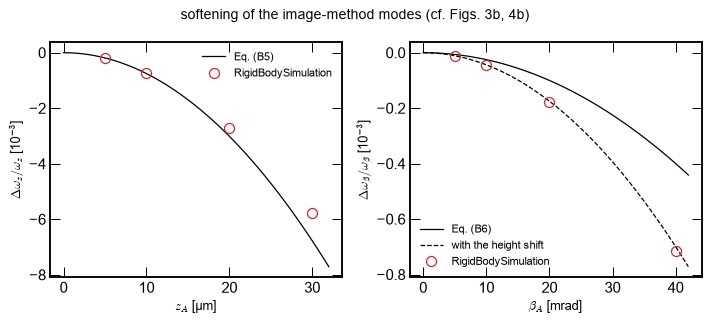

In [3]:
trap, h0 = levitated(30.1e-6)
p = trap.bead
Ωz = np.sqrt(trap.stiffness_tensor[0, 0] / p.m)
Ωβ = np.sqrt(trap.torque_stiffness_tensor[2, 2] / p.inertia_tensor[2, 2])


def frequency(signal, Δt):
    s = signal - signal.mean()
    up = np.flatnonzero((s[:-1] < 0) & (s[1:] >= 0))
    times = (up - s[up] / (s[up + 1] - s[up])) * Δt
    return 2 * π / np.diff(times).mean()


z_amplitudes = np.array([5, 10, 20, 30]) * 1e-6
β_amplitudes = np.array([5, 10, 20, 40]) * 1e-3
z_shift, β_shift = [], []
for z_A in z_amplitudes:
    Δt = 2 * π / Ωz / 400
    sim = RigidBodySimulation(trap=trap, num_samples=20 * 400, Δt=Δt, gas_damping=False, r0=(z_A, 0, 0))
    z_shift.append(frequency(sim.X[:, 0], Δt) / Ωz - 1)
for β_A in β_amplitudes:
    Δt = 2 * π / Ωβ / 400
    tilted = Sphere(30.1e-6, material=MAGNET,
                    orientation=body_axis_to_quaternion((np.sin(β_A), np.cos(β_A), 0)))
    sim = RigidBodySimulation(trap=trap, num_samples=20 * 400, Δt=Δt, gas_damping=False,
                              X0=np.concatenate([np.zeros(6), tilted.orientation, np.zeros(3)]))
    β = np.arcsin(sim.lab_directions((0, 0, 1))[:, 0])
    β_shift.append(frequency(β, Δt) / Ωβ - 1)
z_shift, β_shift = np.array(z_shift), np.array(β_shift)
for z_A, s in zip(z_amplitudes, z_shift):
    print(f'z_A = {z_A * 1e6:4.0f} μm: Δω/ω simulated {s:.3e}, Eq. (B5) {-35 / 48 * z_A**2 / h0**2:.3e}')
for β_A, s in zip(β_amplitudes, β_shift):
    print(f'β_A = {β_A * 1e3:4.0f} mrad: Δω/ω simulated {s:.3e}, Eq. (B6) {-β_A**2 / 4:.3e}, '
          f'with the height shift {-7 * β_A**2 / 16:.3e}')
print(f'fitted β coefficient Δω/ω = c·β_A²: c = {np.polyfit(β_amplitudes**2, β_shift, 1)[0]:.3f} (Eq. (B6): -0.25; with the height shift: -7/16 = -0.4375)')

fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
zz = np.linspace(0, 32e-6, 100)
axes[0].plot(zz * 1e6, -35 / 48 * zz**2 / h0**2 * 1e3, 'k', label='Eq. (B5)')
axes[0].plot(z_amplitudes * 1e6, z_shift * 1e3, 'o', mfc='none', color='C3', label='RigidBodySimulation')
axes[0].set_xlabel(r'$z_A$ [μm]')
axes[0].set_ylabel(r'$\Delta\omega_z/\omega_z$ [10$^{-3}$]')
axes[0].legend(frameon=False, fontsize=9)
bb = np.linspace(0, 42e-3, 100)
axes[1].plot(bb * 1e3, -bb**2 / 4 * 1e3, 'k', label='Eq. (B6)')
axes[1].plot(bb * 1e3, -7 * bb**2 / 16 * 1e3, 'k--', label='with the height shift')
axes[1].plot(β_amplitudes * 1e3, β_shift * 1e3, 'o', mfc='none', color='C3', label='RigidBodySimulation')
axes[1].set_xlabel(r'$\beta_A$ [mrad]')
axes[1].set_ylabel(r'$\Delta\omega_\beta/\omega_\beta$ [10$^{-3}$]')
axes[1].legend(frameon=False, fontsize=9)
fig.suptitle('softening of the image-method modes (cf. Figs. 3b, 4b)', fontsize=11)
fig.tight_layout()

The vertical mode follows Eq. (B5) at small amplitudes (higher orders appear above about 20 μm).
The tilt softens almost twice as fast as Eq. (B6), which keeps z fixed: a tilted moment raises the
image force by (1 + sin²β), so the magnet rises on average by z0·β_A²/8, and since ωβ ∝ z^{-3/2} this
adds −(3/16)β_A² to the −β_A²/4 of Eq. (B6), −(7/16)β_A² in all. In the experiment the β ringdown is
far slower than the z period, so the height follows ⟨sin²β⟩ adiabatically and the same coefficient
applies; the amplitudes the paper infers from Eq. (B6) (3–20 mrad in Fig. 3) would then be about
√(7/4) ≈ 1.3 times too large.

## 3. Gas damping

The paper compares the amplitude decay rates 1/τ with Eqs. (8) and (9) for a sphere in helium at the
cold pressure. levisim's sphere damping (Epstein, as `Trap.Γth`) and its rotational damping
(Martinetz et al. 2018) are momentum damping rates Γ, so 1/τ = Γ/2.

In [4]:
R = 27e-6
trap_gas, _ = levitated(R, P=1 * mbar)
Γ_t = trap_gas.Γth
Γ_r = trap_gas.Γrot_j['γ']
gas = trap_gas.gas
vth = np.sqrt(8 * kB * gas.T / (π * gas.m))
P_Pa = 1 * mbar
inv_τ_t = 0.5 * (1 + 8 / π) * P_Pa / (7430 * R * vth)
inv_τ_r = 5 / π * P_Pa / (7430 * R * vth)
print(f'1/τ per mbar, translation: levisim Γ/2 = {Γ_t / 2:.2f} s⁻¹, Eq. (8) {inv_τ_t:.2f} s⁻¹ (paper 5.96; measured 6.2 ± 0.5)')
print(f'1/τ per mbar, rotation:    levisim Γ/2 = {Γ_r / 2:.2f} s⁻¹, Eq. (9) {inv_τ_r:.2f} s⁻¹ (paper 5.35; measured 5.6 ± 0.3)')
print(f'ratio translation/rotation: levisim {Γ_t / Γ_r:.3f}, Eqs. (8)/(9) {inv_τ_t / inv_τ_r:.3f} (paper ≈ 1.1)')

1/τ per mbar, translation: levisim Γ/2 = 5.93 s⁻¹, Eq. (8) 5.93 s⁻¹ (paper 5.96; measured 6.2 ± 0.5)
1/τ per mbar, rotation:    levisim Γ/2 = 5.32 s⁻¹, Eq. (9) 5.32 s⁻¹ (paper 5.35; measured 5.6 ± 0.3)
ratio translation/rotation: levisim 1.114, Eqs. (8)/(9) 1.114 (paper ≈ 1.1)


## Summary

| Quantity | Paper | levisim | Verdict |
|---|---|---|---|
| levitation height (R = 30.1 μm) | 311 μm | 311 μm | agree |
| ωz/2π, ωβ/2π (R = 30.1 μm) | 56.5 ± 0.1 Hz, 377 ± 5 Hz (measured; image method) | 56.5 Hz, 377.1 Hz (58.9 and 403.6 Hz for the microscope's 27 μm) | agree |
| radius from Eq. (7) | 30.1 ± 0.5 μm | 30.1 ± 0.4 μm | agree |
| softening | Eqs. (B5), (B6) | z on Eq. (B5) at small amplitude; β at −0.446 β_A² against −β_A²/4, explained by the height shift (−7β_A²/16) | z agrees; β differs (the coupling to z that Eq. (B6) neglects) |
| gas damping 1/τ per mbar | 5.96 / 5.35 s⁻¹ (theory), 6.2 / 5.6 s⁻¹ (measured) | 5.93 / 5.32 s⁻¹ (equal to Eqs. (8), (9)) | agree |

Not modelled: the side walls of the well and the tilt (the x, y and α modes), flux pinning and
hysteresis in the lead, the magnetic and eddy-current losses that set the residual damping
(1/τ0 ≈ 4 × 10⁻⁵ s⁻¹ for β), and the SQUID detection.

In [5]:
print(f'computation time {time.time() - t_start:.1f} s')

computation time 20.9 s
